In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Load the dataset
df = pd.read_csv("../dataset/spam.csv", encoding="latin-1")

# Keep only the required columns
df = df[['v1', 'v2']]

# Rename columns
df.columns = ['label', 'message']

# Display first 5 rows
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
# Check dataset information
df.info()

# Count spam and ham messages
df['label'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


label
ham     4825
spam     747
Name: count, dtype: int64

In [6]:
# Check for duplicate messages
print("Duplicate messages:", df.duplicated().sum())

# Remove duplicate messages
df = df.drop_duplicates()

# Check the dataset after removing duplicates
print("Dataset shape after removing duplicates:", df.shape)

Duplicate messages: 403
Dataset shape after removing duplicates: (5169, 2)


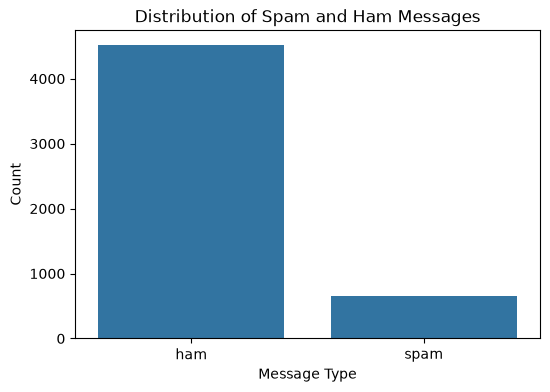

In [8]:
# Visualize the distribution of spam and ham messages

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='label')

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Count")

plt.show()

In [9]:
# Convert messages to lowercase
df['message'] = df['message'].str.lower()

# Display the first 5 messages
df.head()

,label,message
0,ham,"go until jurong point, crazy.. available only ..."
1,ham,ok lar... joking wif u oni...
2,spam,free entry in 2 a wkly comp to win fa cup fina...
3,ham,u dun say so early hor... u c already then say...
4,ham,"nah i don't think he goes to usf, he lives aro..."


In [10]:
# Convert labels into numerical values
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

# Display the first 5 rows
df.head()

,label,message
0,0,"go until jurong point, crazy.. available only ..."
1,0,ok lar... joking wif u oni...
2,1,free entry in 2 a wkly comp to win fa cup fina...
3,0,u dun say so early hor... u c already then say...
4,0,"nah i don't think he goes to usf, he lives aro..."


In [11]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Separate features and target
X = df['message']
y = df['label']

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display dataset sizes
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 4135
Testing data: 1034


In [12]:
# Import TF-IDF Vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer()

# Transform training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing messages
X_test_tfidf = tfidf.transform(X_test)

# Display the shape of the transformed data
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4135, 7591)
Testing data shape: (1034, 7591)


In [13]:
# Import Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Initialize the model
model = MultinomialNB()

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [14]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict the test data
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display accuracy
print("Model Accuracy:", accuracy * 100, "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 95.16441005802709 %

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       903
           1       1.00      0.62      0.76       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.95      0.95      0.95      1034


Confusion Matrix:
[[903   0]
 [ 50  81]]


In [15]:
# Import Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Initialize the model with a different smoothing parameter
model = MultinomialNB(alpha=0.1)

# Train the model
model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred = model.predict(X_test_tfidf)

# Evaluate the model
print("Model Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 98.25918762088975 %

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       903
           1       0.97      0.89      0.93       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034


Confusion Matrix:
[[900   3]
 [ 15 116]]


In [16]:
# Import joblib
import joblib

# Save the trained model
joblib.dump(model, "spam_model.pkl")

# Save the TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [17]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Initialize the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Make predictions
lr_pred = lr_model.predict(X_test_tfidf)

# Evaluate the model
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

Logistic Regression Accuracy: 96.71179883945842 %


In [18]:
from sklearn.metrics import classification_report, confusion_matrix

# Classification Report
print("Logistic Regression Classification Report:")
print(classification_report(y_test, lr_pred))

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       903
           1       0.99      0.75      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.97      1034

Confusion Matrix:
[[902   1]
 [ 33  98]]


In [19]:
from sklearn.model_selection import cross_val_score

# Cross-validation for Naive Bayes
nb_scores = cross_val_score(
    model, X_train_tfidf, y_train,
    cv=5, scoring='accuracy'
)

# Cross-validation for Logistic Regression
lr_scores = cross_val_score(
    lr_model, X_train_tfidf, y_train,
    cv=5, scoring='accuracy'
)

print("Naive Bayes Cross-validation Accuracy:",
      nb_scores.mean() * 100, "%")

print("Logistic Regression Cross-validation Accuracy:",
      lr_scores.mean() * 100, "%")

Naive Bayes Cross-validation Accuracy: 98.25876662636034 %
Logistic Regression Cross-validation Accuracy: 95.06650544135428 %


In [20]:
from sklearn.metrics import roc_auc_score

# Get prediction probabilities
nb_prob = model.predict_proba(X_test_tfidf)[:, 1]
lr_prob = lr_model.predict_proba(X_test_tfidf)[:, 1]

# Calculate ROC-AUC
nb_auc = roc_auc_score(y_test, nb_prob)
lr_auc = roc_auc_score(y_test, lr_prob)

print("Naive Bayes ROC-AUC:", nb_auc)
print("Logistic Regression ROC-AUC:", lr_auc)

Naive Bayes ROC-AUC: 0.994395272754939
Logistic Regression ROC-AUC: 0.9892385855460594


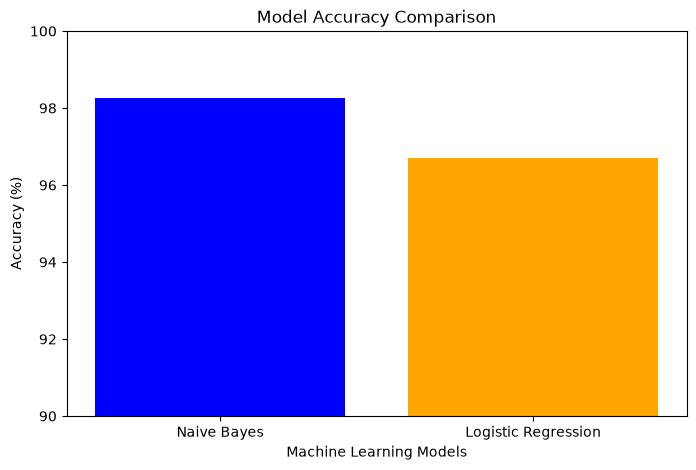

In [21]:
import matplotlib.pyplot as plt

# Model names
models = ['Naive Bayes', 'Logistic Regression']

# Accuracy values
accuracy = [98.25, 96.71]

# ROC-AUC values
roc_auc = [nb_auc, lr_auc]

# Create comparison chart
plt.figure(figsize=(8, 5))

plt.bar(models, accuracy, color=['blue', 'orange'])

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')

plt.ylim(90, 100)

plt.show()

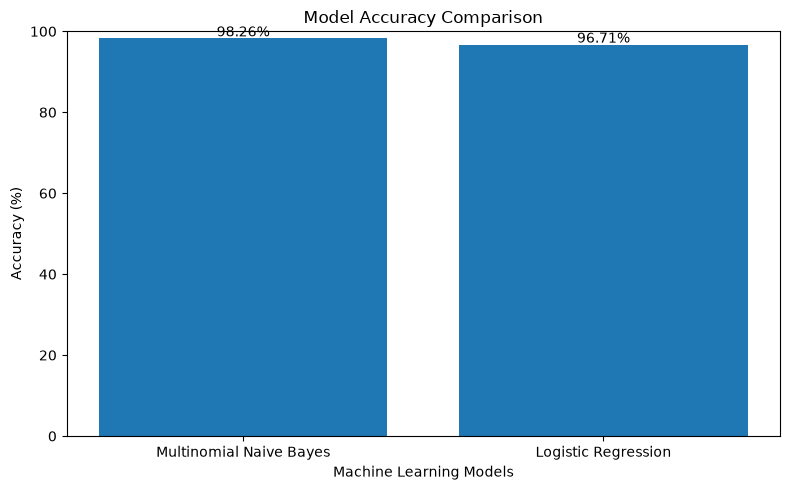

In [25]:
import matplotlib.pyplot as plt
import os

# Model accuracy values
models = ['Multinomial Naive Bayes', 'Logistic Regression']
accuracies = [98.26, 96.71]

# Create bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

# Display accuracy values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 0.5,
             f'{height:.2f}%',
             ha='center')

plt.tight_layout()

# Save plot
os.makedirs('../results/plots', exist_ok=True)
plt.savefig('../results/plots/model_accuracy_comparison.png')

plt.show()

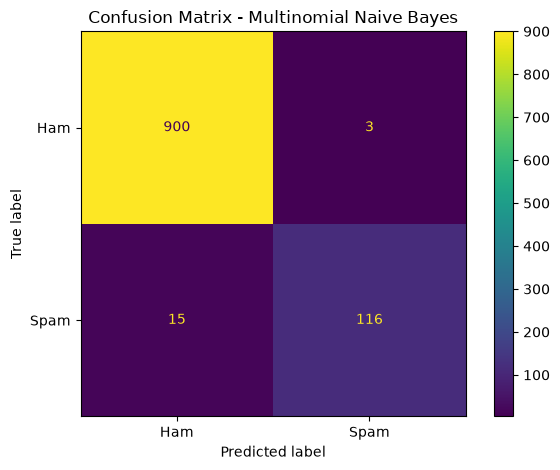

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
)

disp.plot()
plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.tight_layout()

# Save plot
plt.savefig('../results/plots/confusion_matrix.png')
plt.show()

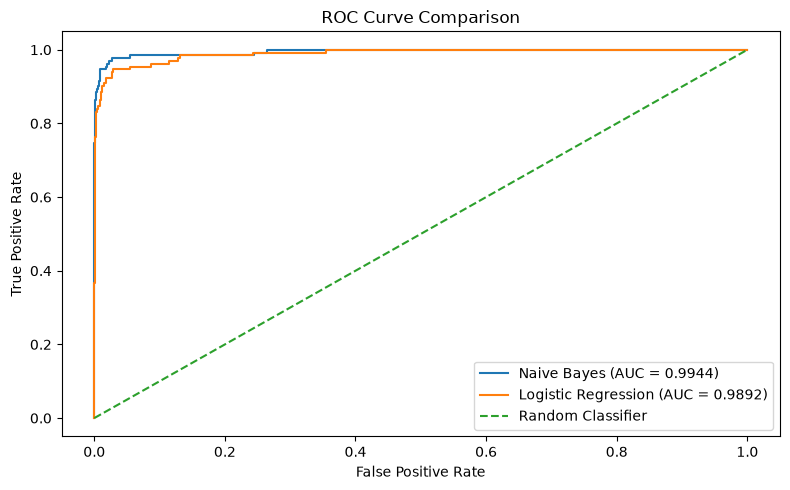

In [27]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Get prediction probabilities
nb_probs = model.predict_proba(X_test_tfidf)[:, 1]
lr_probs = lr_model.predict_proba(X_test_tfidf)[:, 1]

# Calculate ROC curves
nb_fpr, nb_tpr, _ = roc_curve(y_test, nb_probs)
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)

# Calculate AUC
nb_auc = auc(nb_fpr, nb_tpr)
lr_auc = auc(lr_fpr, lr_tpr)

# Plot ROC curves
plt.figure(figsize=(8, 5))
plt.plot(nb_fpr, nb_tpr, label=f'Naive Bayes (AUC = {nb_auc:.4f})')
plt.plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {lr_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()

# Save plot
plt.savefig('../results/plots/roc_curve_comparison.png')
plt.show()